# 03: Modelos na validação (baselines, LSTM e STGCN com e sem grafo)

Este notebook só **lê os resultados** já gerados pelos scripts, sem treinar nada:

```
python -m dengue.baselines         # results/baselines_validacao.csv
python -m dengue.lstm_validacao    # results/lstm_validacao.csv
python -m dengue.stgcn_validacao   # results/stgcn_validacao.csv (geo e identidade)
```

Tudo é medido na **validação (2013 a 2015)**, na escala original da taxa. Os modelos treinados são média ± desvio de 3 seeds. O teste (2016 a 2021) não é usado aqui.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dengue import dados

RES = dados.RAIZ / 'results'
base = pd.read_csv(RES / 'baselines_validacao.csv', index_col='modelo')
lstm = pd.read_csv(RES / 'lstm_validacao.csv', index_col='seed')
stgcn = pd.read_csv(RES / 'stgcn_validacao.csv', index_col='seed')

def media_desvio(tabela):
    return tabela.loc['media'], tabela.loc['desvio']

# Uma linha por modelo: média e desvio (0 para os baselines, que não têm seed)
medias, desvios = {}, {}
for nome in ['persistencia', 'climatologia_mediana']:
    medias[nome], desvios[nome] = base.loc[nome], base.loc[nome] * 0
medias['LSTM'], desvios['LSTM'] = media_desvio(lstm)
for g, rotulo in [('identidade', 'STGCN sem grafo (A = I)'), ('geo', 'STGCN geo')]:
    t = stgcn[stgcn['grafo'] == g].drop(columns='grafo')
    medias[rotulo], desvios[rotulo] = media_desvio(t)
medias, desvios = pd.DataFrame(medias).T, pd.DataFrame(desvios).T
colunas = ['mae', 'rmse', 'mae_surto']
(medias[colunas].round(3).astype(str) + ' ± ' + desvios[colunas].round(3).astype(str))

,mae,rmse,mae_surto
persistencia,0.609 ± 0.0,2.371 ± 0.0,2.144 ± 0.0
climatologia_mediana,0.82 ± 0.0,3.356 ± 0.0,3.257 ± 0.0
LSTM,0.472 ± 0.005,2.067 ± 0.036,1.643 ± 0.04
STGCN sem grafo (A = I),0.457 ± 0.009,1.938 ± 0.008,1.575 ± 0.022
STGCN geo,0.459 ± 0.011,1.913 ± 0.029,1.594 ± 0.037


### Pergunta 1: os modelos treinados superam os baselines ingênuos?

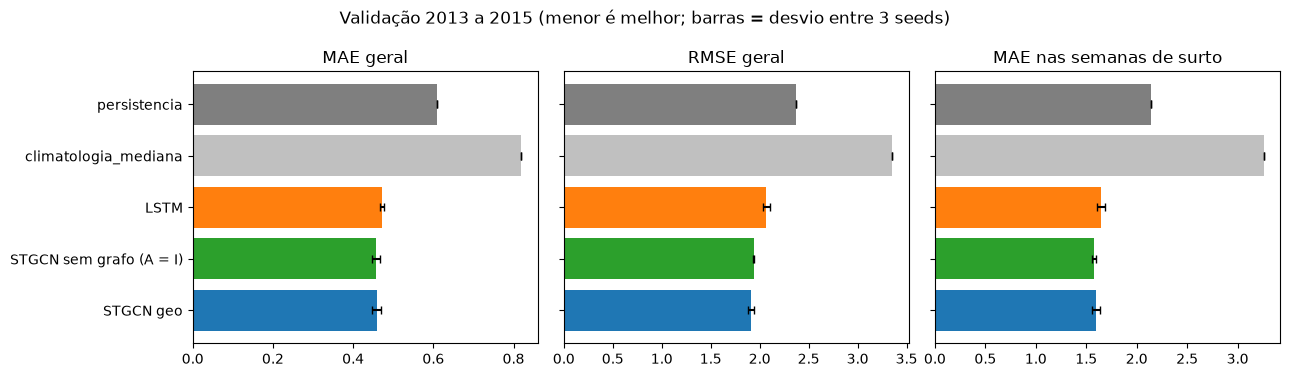

In [2]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
titulos = {'mae': 'MAE geral', 'rmse': 'RMSE geral', 'mae_surto': 'MAE nas semanas de surto'}
cores = ['tab:gray', 'silver', 'tab:orange', 'tab:green', 'tab:blue']
for ax, m in zip(eixos, colunas):
    ax.barh(medias.index, medias[m], xerr=desvios[m], color=cores, capsize=3)
    ax.set_title(titulos[m])
    ax.invert_yaxis()
for ax in eixos[1:]:
    ax.set_yticklabels([])
fig.suptitle('Validação 2013 a 2015 (menor é melhor; barras = desvio entre 3 seeds)')
plt.tight_layout()
plt.show()

**Conclusão:** sim. Os três modelos treinados ficam bem abaixo da persistência e da climatologia nas três métricas. O MAE cai de 0,61 (persistência) para cerca de 0,46 (STGCN), uma redução de aproximadamente 25%. Entre os treinados, os dois STGCN superam o LSTM em MAE, RMSE e MAE de surto. A climatologia é o pior baseline: a dengue varia muito de um ano para outro, e a média histórica da semana não acompanha os surtos.

### Pergunta 2: como o erro cresce quando prevemos mais longe (h = 1 a 4 semanas)?

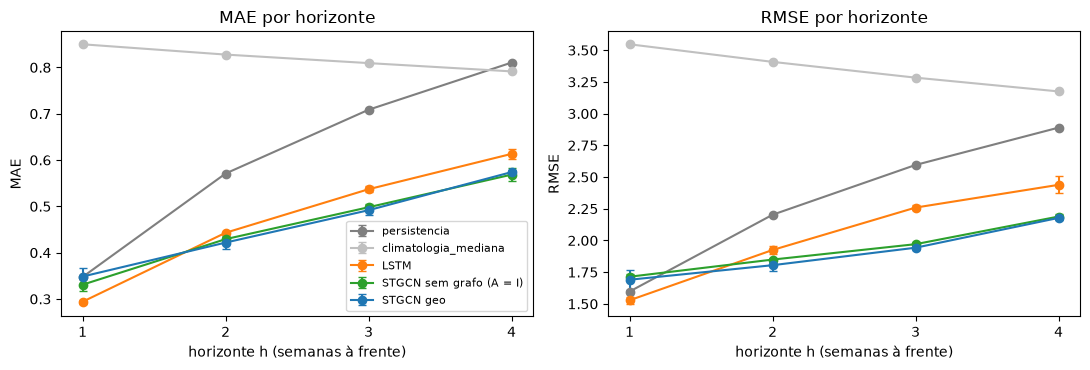

In [3]:
h = np.arange(1, dados.H + 1)
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for nome, cor in zip(medias.index, cores):
    for ax, m in zip(eixos, ['mae', 'rmse']):
        cols = [f'{m}_h{i}' for i in h]
        ax.errorbar(h, medias.loc[nome, cols], yerr=desvios.loc[nome, cols],
                    marker='o', color=cor, label=nome, capsize=3)
for ax, m in zip(eixos, ['MAE', 'RMSE']):
    ax.set(xlabel='horizonte h (semanas à frente)', ylabel=m, xticks=h,
           title=f'{m} por horizonte')
eixos[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Conclusão:** o erro de todos os modelos cresce com h, menos o da climatologia, que não usa as semanas recentes e por isso fica quase igual em qualquer horizonte. Em h = 1, repetir a última semana já é difícil de bater: a persistência empata com os STGCN (≈ 0,35), e o LSTM é o melhor modelo (0,29). Mas o erro do LSTM cresce mais rápido, e a partir de h = 2 os STGCN passam à frente, com a vantagem aumentando até h = 4. O ganho do STGCN está nas previsões mais longas, que são as mais úteis para a vigilância se preparar.

### Pergunta 3: o grafo geográfico ajuda? (STGCN geo × STGCN sem grafo)

As duas versões têm a mesma arquitetura e o mesmo treino. A única diferença é a matriz do grafo: no controle, `L~ = I`, então cada município só olha o próprio passado. Assim, qualquer diferença entre os dois vem do grafo.

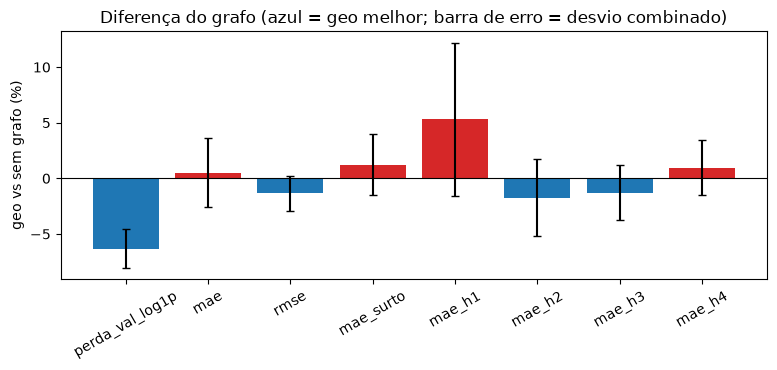

,geo,sem grafo,variação %
perda_val_log1p,0.098,0.104,-6.316
mae,0.459,0.457,0.504
rmse,1.913,1.938,-1.326
mae_surto,1.594,1.575,1.206
mae_h1,0.348,0.331,5.319
mae_h2,0.422,0.429,-1.724
mae_h3,0.492,0.498,-1.285
mae_h4,0.574,0.568,0.967


In [4]:
metr = ['perda_val_log1p', 'mae', 'rmse', 'mae_surto'] + [f'mae_h{i}' for i in h]
geo, ide = 'STGCN geo', 'STGCN sem grafo (A = I)'
variacao = 100 * (medias.loc[geo, metr] - medias.loc[ide, metr]) / medias.loc[ide, metr]
ruido = 100 * np.hypot(desvios.loc[geo, metr], desvios.loc[ide, metr]) / medias.loc[ide, metr]

fig, ax = plt.subplots(figsize=(8, 3.8))
cor = ['tab:blue' if v < 0 else 'tab:red' for v in variacao]
ax.bar(metr, variacao, yerr=ruido, color=cor, capsize=3)
ax.axhline(0, color='black', lw=0.8)
ax.set(ylabel='geo vs sem grafo (%)',
       title='Diferença do grafo (azul = geo melhor; barra de erro = desvio combinado)')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()
pd.DataFrame({'geo': medias.loc[geo, metr], 'sem grafo': medias.loc[ide, metr],
              'variação %': variacao}).round(3)

**Conclusão:** o grafo ajuda pouco, e de forma mista:

- **A favor do geo:** a perda de treino (MSE em `log1p`) na validação é cerca de 6% menor, e o RMSE dos horizontes mais longos (h = 2 e 3) também é menor.
- **A favor do sem grafo:** o MAE em h = 1 e o MAE nas semanas de surto são levemente melhores.
- **No MAE geral, os dois empatam:** 0,459 contra 0,457, uma diferença menor que o desvio entre as seeds.

Isso repete o que o projeto antigo encontrou e o que a task 15 previa, já que a correlação entre vizinhos é só um pouco maior que entre pares aleatórios. **O ganho sobre o LSTM vem da arquitetura** (convolução temporal com porta, residual e previsão de todos os nós juntos), não do grafo. O grafo geo continua sendo o modelo principal porque tem a menor perda na validação, que é o critério de escolha. Mas na banca é preciso dizer com clareza que a vizinhança geográfica acrescenta pouco no RJ.